# Projection and Label Transfer

This tutorial demonstrates how to project other datasets into HypoMap3D's single cell embedding space for label transfer.

In this notebook, we will:
1. Project query cells (such as your own data) into HypoMap3D's embedding space (scArches)
2. Transfer labels and membership probabilities 
3. Project the query cells into HypoMap3D's UMAP space

Requirements:
1. HypoMap3D's code base and environment. For this, follow the instructions at the root of the Git repo.
2. HypoMap3D single cell atlas. Download it and place it into DATADIR/9_objects/singlecell/hypomap3d_singlecell_all.h5ad
3. HypoMap3D's scVI model. Download it and place it into DATADIR/9_objects/scvi/model.pt
4. Your own query dataset.

Of course, the above paths can be modified but then they have to be changed accordingly below as well.

### Imports

In [30]:
from pathlib import Path
import warnings
import os 

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scvi
import matplotlib.pyplot as plt
from dotenv import dotenv_values
import torch
import scipy.sparse as sp

from hm3d_utils.manifold import project_to_ref_umap
from hm3d_utils.clustering import project_query

warnings.simplefilter(action='ignore', category=FutureWarning)
sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)
scvi.settings.seed = 12345

use_gpu = torch.cuda.is_available()
print(f"GPU is available: {use_gpu}")

Seed set to 12345


GPU is available: True


### File paths

The following ones are automatic and only require a change if you downloaded the files somewhere else.

In [3]:
CONFIG = dotenv_values("config.env") # file at the root of your cloned repo
DATADIR = Path(CONFIG['DATADIR']) # root of your DATADIR

# Path to director of scVI model
SCVI_DIR  = DATADIR / "9_objects" / "scvi"

# Path to reference object
REF_FP = DATADIR / "9_objects" / "singlecell" / "hypomap3d_singlecell_all.h5ad" 

The following cell contains the path to your data, so change the path accordingly, and remove the "#". 

In this notebook, we will use the non-control cells from the Gutgesell dataset for demonstration if QUERY_FP remains undefined.

In [ ]:
# QUERY_FP = Path("path/to/your/data.h5ad") #change and uncomment me if you want to use your own data

# Data loading

Let's load the reference (HypoMap3D)

In [20]:
ref_adata = sc.read_h5ad(REF_FP, backed="r") 
ref_adata = ref_adata[ref_adata.obs.IsControl].to_memory() # projection and label transfer are performed on control cells only

In [21]:
ref_adata

AnnData object with n_obs × n_vars = 896959 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

Let's load the query adata.

If you provided the path to your object above it will be used. 

Otherwise, a subset of HypoMap3D's non-control data will be used, deleting some genes in the process as to simulate a dataset that might not cover all of HypoMap3D's feature space.

In [8]:
if "QUERY_FP" in globals():
    query_adata = sc.read_h5ad(QUERY_FP) #load user dataset
else:
    import random
    query_adata = sc.read_h5ad(REF_FP, backed="r")

    # Randomly remove 10% of HypoMap3D's HVGs
    hvgs = ref_adata.var.loc[ref_adata.var.IsHvg].index.to_list()
    genes_to_remove = set(random.sample(hvgs, k=len(hvgs) // 10))

    gene_subset = [g for g in query_adata.var_names if g not in genes_to_remove]

    # Load non-control cells of Gutgesell dataset
    query_adata = query_adata[
        (query_adata.obs.Dataset == "SC2-25") & (~query_adata.obs.IsControl),
        gene_subset
    ].to_memory()

    # Remove information to get barebone query
    query_adata.obs = query_adata.obs.loc[:, ["CellID", "Sample"]]
    del query_adata.obsm

In [9]:
query_adata

AnnData object with n_obs × n_vars = 121626 × 56489
    obs: 'CellID', 'Sample'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'

# scArches projection

## Preparation

### Raw counts sanity check

scArches operates on raw counts, so you need to ensure that query_adata.X contains raw counts!

Here, we just print the frequency distribution of some gene count values for simplicity.

In [10]:
value_counts = pd.Series(query_adata[:100,:100].X.toarray().flatten()).value_counts().sort_index() 
value_counts.head(10)

0.0    9634
1.0     166
2.0      52
3.0      32
4.0      29
5.0      12
6.0      18
7.0       6
8.0      11
9.0       9
Name: count, dtype: int64

In [11]:
value_counts.tail(10)

14.0    2
18.0    2
19.0    3
22.0    1
23.0    1
24.0    1
27.0    1
28.0    1
37.0    1
48.0    1
Name: count, dtype: int64

All numbers on the left are floats with 0 as decimals --> raw counts. 

### Setting batch column

Next, we must set the batch column for scArches. This will be the .obs column specifying your sample for instance

In [12]:
query_adata.obs.head(2)

,CellID,Sample
SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599
SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599


In [56]:
BATCH_COL = "Sample" # change me if your data uses a different name

The problem is that the name of the batch column MUST be "Sample" due to the model specifications.

Hence, we use your provided BATCH_COL, replacing its column name with Sample in the query adata.

DO not worry, the object that is being saved later is the object with all genes. Hence, your previous column name will be maintained. 

In [ ]:
query_adata.obs = query_adata.obs.rename(columns={BATCH_COL: "Sample"})

### Copy query data with all genes

Non-HVGs are lost during the projection, so let's keep a version that has all genes for later.

In [14]:
query_all_genes = query_adata.copy()

In [15]:
query_adata

AnnData object with n_obs × n_vars = 121626 × 56489
    obs: 'CellID', 'Sample'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'

### Query preparation according to model

In [16]:
# prepare query adata
query_adata = scvi.model.SCVI.prepare_query_anndata(query_adata, str(SCVI_DIR), inplace = False)

INFO     File /REDACTED-path/HypoMap3D-data/v0.9/9_objects/scvi/model.pt already downloaded           


INFO     Found 90.0% reference vars in query data.                                                                 


In [17]:
# create the new query model instance.
vae_query = scvi.model.SCVI.load_query_data(
    query_adata,
    str(SCVI_DIR)
)

# train
vae_query.train(max_epochs=20, plan_kwargs=dict(weight_decay=0.0))

INFO     File /REDACTED-path/HypoMap3D-data/v0.9/9_objects/scvi/model.pt already downloaded           


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A40') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/beegfs/home/mfeldmann/repos/HypoMap3D/.venv/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in th

Training:   0%|          | 0/20 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.


In [18]:
# get latent representation into query adata that has all genes
query_all_genes.obsm["X_embed"] = vae_query.get_latent_representation()

# Label transfer

### Step 1: Let's get membership probabilities for L5 cell types

This is performed by the project_query function in a hierarchy-aware manner where the most probable path along the clustering tree is chosen.

In [22]:
pathmat, P_path = project_query(
    ref_adata,
    query_all_genes,
    path_keys=[f'L{i}_ID' for i in range(1,6)],
    k=50,
    use_rep='X_embed',
    use_gpu=use_gpu
)

2026-08-08 10:31:51 | [WARNING] 
            Precomputed reference neighbor adjacencies, `.obsp['50nn_adjacencies']`, not found. 
            Computing reference 50 neighbors and adding to `.obsp['50nn_adjacencies']`.
            


The output of the project query function is a matrix of shape (n_cells, n_unique_L5_labels) containing the cell type membership probabilities for all L5 cell types.

In [25]:
P_path

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 355999 stored elements and shape (121626, 932)>

Further, pathmat tells us the paths from L1 to L5 along our clustering tree for each of the n_unique_L5_labels.

In [23]:
pathmat

array([['Gb1-2', 'Gb2-39', 'Gb3-124', 'Gb4-319', 'Gb5-428'],
       ['Gb1-2', 'Gb2-39', 'Gb3-124', 'Gb4-320', 'Gb5-429'],
       ['Gb1-2', 'Gb2-39', 'Gb3-124', 'Gb4-321', 'Gb5-430'],
       ...,
       ['NN1-4', 'NN2-14', 'NN3-28', 'NN4-44', 'NN5-44'],
       ['NN1-4', 'NN2-14', 'NN3-28', 'NN4-45', 'NN5-45'],
       ['NN1-4', 'NN2-14', 'NN3-28', 'NN4-46', 'NN5-46']],
      shape=(932, 5), dtype=object)

Pathmat is required during smoothing, so let us keep it in the adata.

In [ ]:
query_all_genes.uns["pathmat"] = pathmat

### Step 2: Let's get hard cell type assignments for all levels

To get a hard cell type assignment, we will use the cell type with the highest probabilities.

However, before doing so, let us prepare some cell type label mappers as to map our abc-like as well as our short from descriptive labels into obs next to the level-specific IDs.

In [26]:
def build_id_mapping(n_df, id_pattern, target_pattern, levels=range(1, 6),):
    mapping = {}

    # --- 1. from wide dataframe ---
    for i in levels:
        id_col = id_pattern.format(i=i)
        target_col = target_pattern.format(i=i)

        if id_col in n_df.columns and target_col in n_df.columns:
            mapping.update(
                n_df[[id_col, target_col]]
                .dropna()
                .drop_duplicates()
                .set_index(id_col)[target_col]
                .to_dict()
            )

    return mapping

In [27]:
abclike_mapper = build_id_mapping(ref_adata.obs,
    id_pattern="L{i}_ID",
    target_pattern="L{i}_abc_like")

descr_mapper = build_id_mapping(ref_adata.obs,
    id_pattern="L{i}_ID",
    target_pattern="L{i}_descr") 


Now, as to get cell type labels and label transfer confidences for all levels above L5, we add up cell type membership probabilities of all leaf cell types in a given branch to create the membership probabilities of the above levels.

So for a given L4 cell type, we sum up the probabilities of all its L5 subclusters.

The same operation is performed up until L1.

We also keep the path probabilities for all levels separately and add them to the query adata.

In [31]:

def build_map_matrix(leaves_to_level):

    leaves_to_level = np.asarray(leaves_to_level)
    level_names, inv = np.unique(leaves_to_level, return_inverse=True)
    rows = inv
    cols = np.arange(len(leaves_to_level))
    data = np.ones(len(leaves_to_level), dtype=np.uint8)
    M = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(len(level_names), len(leaves_to_level)),
    ).tocsr()   

    return M, level_names

def propagate_confidences(adata, pathmat, P_path):

    # Build index maps

    level_maps = [] # 4 arrays indicating the cluster label of the path at Level i
    level_labels = {} # 4 keys, one for each level, mapping to arrays of unique cluster labels

    for lvl in range(4):
        labels = pathmat[:, lvl]
        level_labels[lvl] = np.unique(labels)
        level_maps.append(labels)

    # sum up 

    P_levels = {}

    for lvl in range(4):
        M, ids = build_map_matrix(level_maps[lvl])
        
        # (cells × leaves) @ (leaves × level_nodes)^T
        # Multiplying the cell × L5 probability matrix with M.T sums the
        # probabilities of all leaves belonging to the same parent cluster.
        P_lvl = P_path @ M.T
        
        P_levels[f"L{lvl+1}"] = P_lvl
        adata.uns[f"L{lvl+1}_ID"] = ids
        adata.uns[f"L{lvl+1}_descr"] = [descr_mapper[i] for i in ids]
        adata.uns[f"L{lvl+1}_abc_like"] = [abclike_mapper[i] for i in ids]
        adata.obsm[f"P_L{lvl+1}"] = P_lvl

    ids = pathmat[:, 4]
    adata.uns[f"L5_ID"] = ids
    adata.uns[f"L5_descr"] = [descr_mapper[i] for i in ids]
    adata.uns[f"L5_abc_like"] = [abclike_mapper[i] for i in ids]
    adata.obsm[f"P_L5"] = P_path

    for lvl in range(1, 6):
        P = adata.obsm[f"P_L{lvl}"]

        max_idx = np.asarray(P.argmax(axis=1)).ravel()
        max_prob = np.asarray(P.max(axis=1).toarray()).ravel()

        descr = np.asarray(adata.uns[f"L{lvl}_descr"])
        abc = np.asarray(adata.uns[f"L{lvl}_abc_like"])

        adata.obs[f"L{lvl}_descr_max_p"] = descr[max_idx]
        adata.obs[f"L{lvl}_abc_like_max_p"] = abc[max_idx]
        adata.obs[f"L{lvl}_max_p"] = max_prob

In [32]:
propagate_confidences(query_all_genes, pathmat, P_path)

In [38]:
query_all_genes

AnnData object with n_obs × n_vars = 121626 × 56489
    obs: 'CellID', 'Sample', 'L1_descr_max_p', 'L1_abc_like_max_p', 'L1_max_p', 'L2_descr_max_p', 'L2_abc_like_max_p', 'L2_max_p', 'L3_descr_max_p', 'L3_abc_like_max_p', 'L3_max_p', 'L4_descr_max_p', 'L4_abc_like_max_p', 'L4_max_p', 'L5_descr_max_p', 'L5_abc_like_max_p', 'L5_max_p'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'L1_ID', 'L1_descr', 'L1_abc_like', 'L2_ID', 'L2_descr', 'L2_abc_like', 'L3_ID', 'L3_descr', 'L3_abc_like', 'L4_ID', 'L4_descr', 'L4_abc_like', 'L5_ID', 'L5_descr', 'L5_abc_like'
    obsm: 'X_embed', 'P_L1', 'P_L2', 'P_L3', 'P_L4', 'P_L5'

Now, the most likely labels for L1-L5 along with their confidences are in .obs.

For instance, L2_abc_like_max_p and L2_descr_max_p are the most probable abc-like and short-form labels for L2 with L2_max_p specifying the membership probability (= confidence).

In [35]:
query_all_genes.obs.head(2)

,CellID,Sample,L1_descr_max_p,L1_abc_like_max_p,L1_max_p,L2_descr_max_p,L2_abc_like_max_p,L2_max_p,L3_descr_max_p,L3_abc_like_max_p,L3_max_p,L4_descr_max_p,L4_abc_like_max_p,L4_max_p,L5_descr_max_p,L5_abc_like_max_p,L5_max_p
SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599_AAACAGCCAAGGTACG,SC2-25_SAMN46505599,Gl1-1 Glut,Gl1-1 Glut,1.0,Gl2-4 STN-PSTN Pitx2.Angpt1,Gl2-4 STN-PSTN Pitx2 Angpt1 Glut,1.0,Gl3-8 PSTN Egfem1,Gl3-8 STN-PSTN Pitx2 Angpt1 Glut_1,1.0,Gl4-17 PSTN Egfem1.Grp,Gl4-17 STN-PSTN Pitx2 Angpt1 Glut_1-3,1.0,Gl5-20 PSTN Egfem1.Grp,Gl5-20 STN-PSTN Pitx2 Angpt1 Glut_1-3-1,1.0
SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599_AAACAGCCAATAGCAA,SC2-25_SAMN46505599,NN1-1 OPC-Oligo,NN1-1 OPC-Oligo,1.0,NN2-1 Oligo_1,NN2-1 Oligo_1,1.0,NN3-1 Oligo_1_1,NN3-1 Oligo_1_1,1.0,NN4-1 Oligo_1_1-1,NN4-1 Oligo_1_1-1,1.0,NN5-1 Oligo_1_1-1,NN5-1 Oligo_1_1-1,1.0


Membership probabilities for all cell types are in .obsm, with one matrix per level.

For instance, for L3:

In [39]:
query_all_genes.obsm["P_L3"]

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 223202 stored elements and shape (121626, 274)>

The cell type labels are stored in .uns:

In [42]:
query_all_genes.uns["L3_descr"][:10] # printing just the first 10

['Gb3-124 MPO Meis1',
 'Gb3-125 SI Lgr5',
 'Gb3-126 MPO Sema3d',
 'Gb3-127 MPO Penk',
 'Gb3-128 SI Chat',
 'Gb3-129 NDB Fign',
 'Gb3-130 ZI Hmcn1',
 'Gb3-131 LHA Arx',
 'Gb3-132 CP Nfix',
 'Gb3-133 ZI Onecut3']

So, if you would want to get the membership probability for the cell type "Gb3-228 ARH Agrp" of a particular cell you could use:

In [59]:
agrp_idx = list(query_all_genes.uns["L3_ID"]).index("Gb3-228")
cell_idx = 5 # let's just use the sixth cell here as an example

p_agrp = query_all_genes.obsm["P_L3"][cell_idx, agrp_idx]
p_agrp

np.float32(0.0)

Looks like that cell is not an AgRP neuron!

# Common UMAP

Now we will project the query data into UMAP space of HypoMap3D for some sweet plots.

In [49]:
# Saving previous UMAP coordinates as to not overwrite them
if "X_umap" in query_all_genes.obsm.keys():
    query_all_genes.obsm["X_umap_own"] = query_all_genes.obsm["X_umap"].copy()

In [50]:
query_all_genes.obsm['X_umap'], _ = project_to_ref_umap(
    ref_adata.obsm['X_embed'], # ref embedding
    query_all_genes.obsm['X_embed'], # query embedding
    ref_adata.obsm['X_umap'], # ref umap
    spread=1.0,
    min_dist=0.5,
    verbose=True,
    use_gpu=use_gpu,
    n_epochs=100,
    seed=0
)

  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs


Let's plot your cells on HypoMap3D background

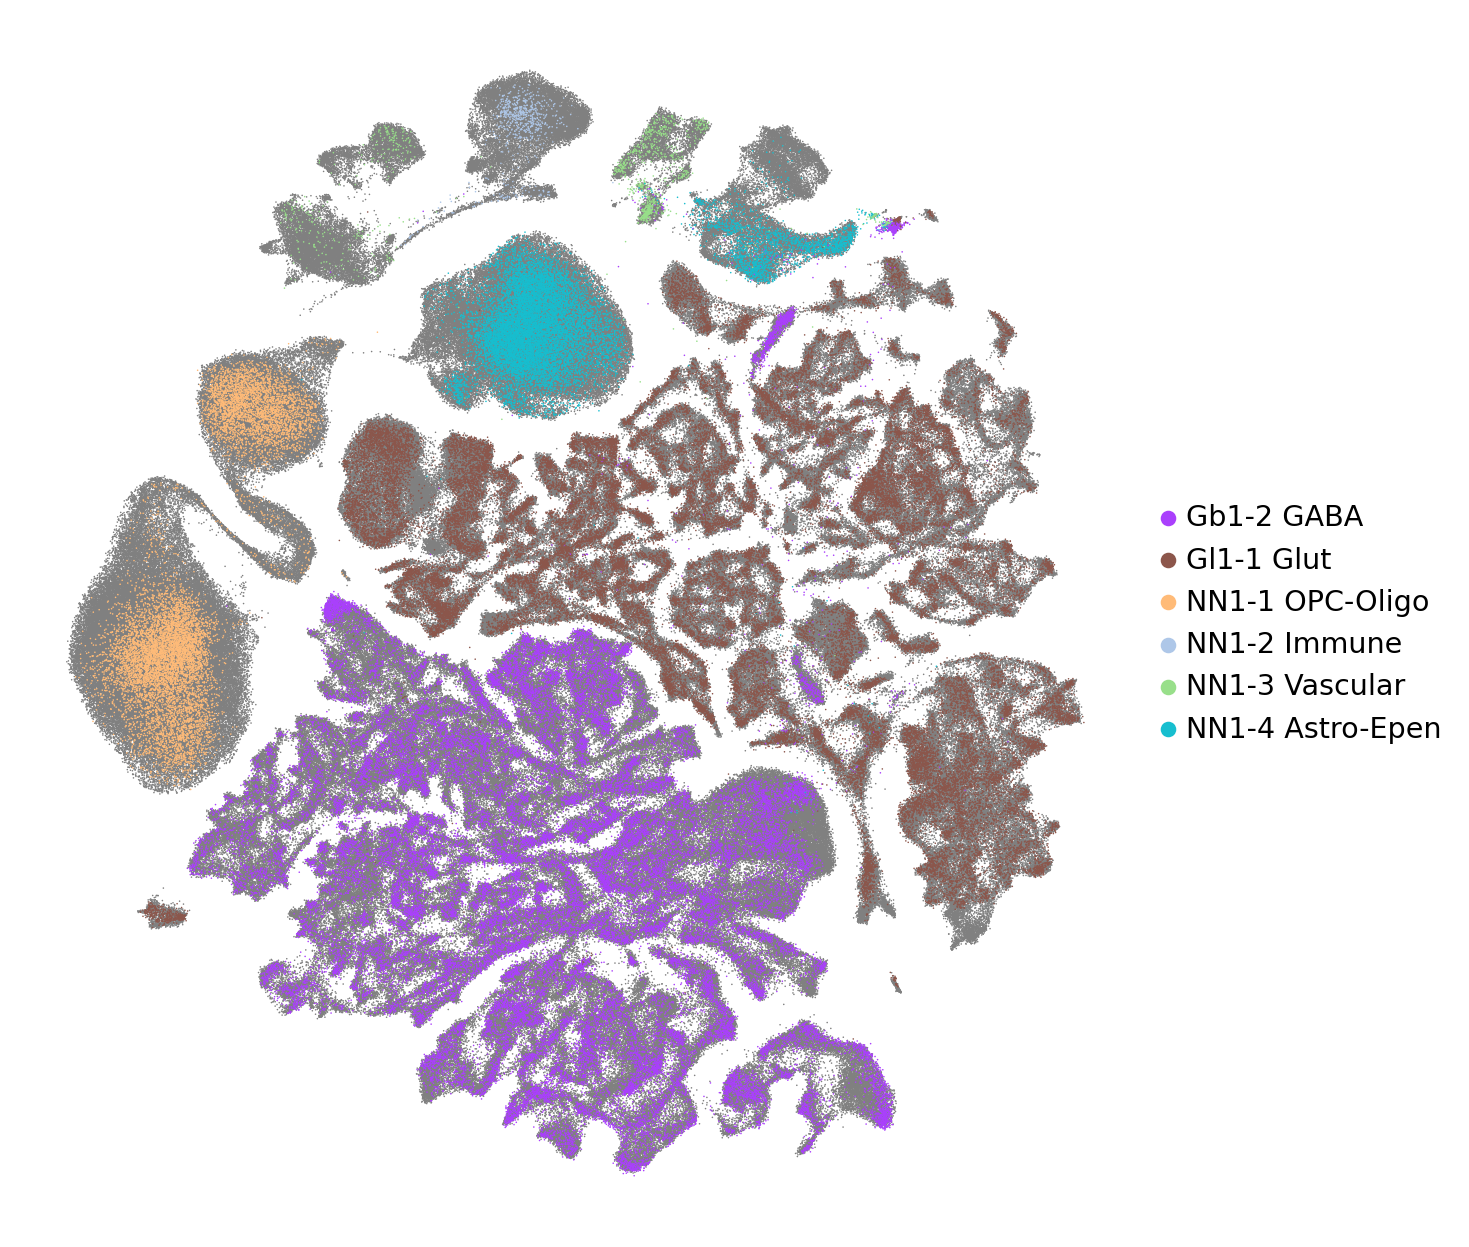

In [55]:
l1_colors = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}

scattersize=2

fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot SC cells in gray
sc.pl.umap(
    ref_adata,
    color="L1_descr",  
    ax=ax,
    show=False,
    palette=["grey"], 
    s=scattersize,
    legend_loc=None
)

# 2. Plot own cells with L1 palette
sc.pl.umap(
    query_all_genes,
    color="L1_descr_max_p",
    palette=l1_colors,  
    ax=ax,
    show=False,
    s=scattersize,
)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

# Saving the adata

Change the path to your heart's content.

In [ ]:
OUT_PATH = "path/to/your/directory/adata_with_hypomap3d_labels.h5ad"  

In [ ]:
query_all_genes.write_h5ad(OUT_PATH)